In [2]:
from google.colab import files
uploaded = files.upload()

!unzip Construction_Safety_Detection.zip -d /content/dataset

Streaming output truncated to the last 5000 lines.
  inflating: /content/dataset/Construction Safety Detection/train/images/autox5_mp4-34_jpg.rf.3c78d4783f9d8451aa12e1a2177ec740.jpg  
  inflating: /content/dataset/Construction Safety Detection/train/images/autox5_mp4-34_jpg.rf.9355e6d129f90d4f5be17f3f93259086.jpg  
  inflating: /content/dataset/Construction Safety Detection/train/images/autox5_mp4-34_jpg.rf.cc87f9ec9778844aea62a27a0ad2130f.jpg  
  inflating: /content/dataset/Construction Safety Detection/train/images/autox5_mp4-34_jpg.rf.e0c7d0632b6b6ec9aae7b89a2b096bea.jpg  
  inflating: /content/dataset/Construction Safety Detection/train/images/autox6_mp4-157_jpg.rf.0bb6fec008de80af30afd18d1a6c676f.jpg  
  inflating: /content/dataset/Construction Safety Detection/train/images/autox6_mp4-157_jpg.rf.5083cfa42053e2766397344e36be6ca8.jpg  
  inflating: /content/dataset/Construction Safety Detection/train/images/autox6_mp4-157_jpg.rf.6691e2b4c1959679de0f67afd80747fe.jpg  
  inflating: /c

In [6]:
import glob

yaml_files = glob.glob('/content/dataset/**/data.yaml', recursive=True)

if yaml_files:
    yaml_path = yaml_files[0]
    print(f"Success! Found data.yaml at: {yaml_path}")
else:
    print("Oops! data.yaml Pls, check Folder")

Success! Found data.yaml at: /content/dataset/Construction Safety Detection/data.yaml


In [9]:
import yaml

yaml_path = '/content/dataset/Construction Safety Detection/data.yaml'

with open(yaml_path, 'r') as f:
    data_dict = yaml.safe_load(f)

data_dict['path'] = '/content/dataset/Construction Safety Detection'
data_dict['train'] = 'train/images'
data_dict['val'] = 'valid/images'
data_dict['test'] = 'test/images'

with open(yaml_path, 'w') as f:
    yaml.dump(data_dict, f, default_flow_style=False)

print("data.yaml successfully updated for Google Colab!")

data.yaml successfully updated for Google Colab!


In [10]:
!pip install -q ultralytics

import yaml
from ultralytics import YOLO

with open(yaml_path, 'r') as stream:
    print(yaml.safe_load(stream))

model = YOLO('yolov8n.pt')

results = model.train(
    data=yaml_path,
    epochs=25,
    imgsz=640,
    batch=16
)

print("Training Completed Successfully!")

{'names': ['Hardhat', 'Mask', 'NO-Hardhat', 'NO-Mask', 'NO-Safety Vest', 'Person', 'Safety Cone', 'Safety Vest', 'machinery', 'vehicle'], 'nc': 10, 'path': '/content/dataset/Construction Safety Detection', 'test': 'test/images', 'train': 'train/images', 'val': 'valid/images'}
Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset/Construction Safety Detection/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fra


image 1/1 /content/dataset/Construction Safety Detection/test/images/IMG_0871_MOV-12_jpg.rf.36858a9d51613f9a39b7855b54dfa098.jpg: 640x640 1 Mask, 1 NO-Hardhat, 1 NO-Safety Vest, 1 Person, 12.5ms
Speed: 1.0ms preprocess, 12.5ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 640)


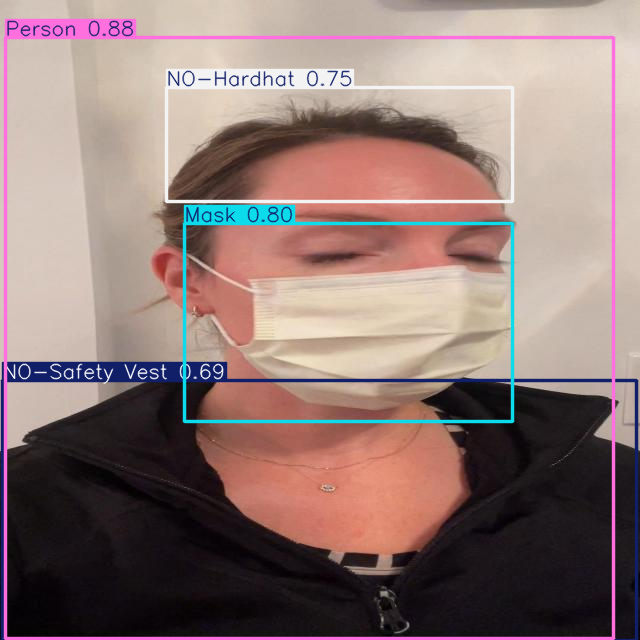

In [14]:
from ultralytics import YOLO
import cv2
from google.colab.patches import cv2_imshow

model = YOLO('/content/runs/detect/train-2/weights/best.pt')

import os
test_image_path = os.path.join('/content/dataset/Construction Safety Detection/test/images', os.listdir('/content/dataset/Construction Safety Detection/test/images')[0])

results = model(test_image_path)

for r in results:
    im_array = r.plot()
    cv2_imshow(im_array)